# 08. Устойчивость многоклассовой mDeBERTa: seed 123 и 2026

**Задача:** независимо повторить конфигурацию `text_standard`, изменив **только random seed**. Это проверка устойчивости, а не очередной поиск лучшего результата.

- **Уже обучено:** `text_standard`, seed **42**, validation Macro F1 **0.750028** — получено в прежнем Kaggle Notebook; **повторно не обучаем**.
- **В этом ноутбуке:** seed **123** и **2026**.
- **Общее для всех трёх:** `microsoft/mdeberta-v3-base`, вход — **только `text_fragment`**, стандартная Cross Entropy, `max_length=256`, LR `2e-5`, эффективный batch **16**, максимум **6 эпох**, выбор лучшего checkpoint по validation Macro F1, Early Stopping (patience 2).
- **Датасет неизменён**, те же train и validation. **Test не оценивается** и ни на что не влияет.

Код предусматривает сохранение `seed_stability.csv`, графики, история эпох, `metrics.json`, `valid_predictions.csv` и **веса обеих новых моделей**. При сравнении seed 42 используется **сохранённая фактическая метрика**, а не новое обучение.

Среда эксперимента — Kaggle с GPU; исходный CSV и конфигурация совпадают с основной серией.

## 1. Зависимости и окружение

In [1]:
import os,sys,subprocess,importlib.util
os.environ['USE_TF']='0'
os.environ['USE_FLAX']='0'
os.environ['TOKENIZERS_PARALLELISM']='false'
missing=[p for p in ('transformers','accelerate','sentencepiece','safetensors') if importlib.util.find_spec(p) is None]
if missing:
    print('Устанавливаю отсутствующие:',missing)
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
    print('После установки библиотек может потребоваться перезапуск ядра.')

## 2. Данные, метрики и конфигурации (строго как в исходном обучении)

In [2]:
import gc,math,time,inspect,shutil,torch,hashlib
import torch.nn.functional as F
from transformers import (AutoTokenizer,AutoModelForSequenceClassification,Trainer,
                          TrainingArguments,DataCollatorWithPadding,EarlyStoppingCallback,set_seed)
import transformers,accelerate

from pathlib import Path
import json, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)
LABELS = ['no_risk','cyber_risk','operational_risk','regulatory_risk']
ID2LABEL = {i:label for i,label in enumerate(LABELS)}
LABEL2ID = {label:i for i,label in ID2LABEL.items()}
EXPECTED_SHA256 = '52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3'

def locate_dataset():
    candidates = [Path.cwd()/'data'/'bank_risk_dataset.csv',
                  Path.cwd()/'bank_risk_dataset.csv',
                  Path.cwd().parent/'data'/'bank_risk_dataset.csv',
                  Path('/kaggle/working/bank_risk_dataset.csv')]
    candidates += sorted(Path('/kaggle/input').rglob('bank_risk_dataset.csv')) if Path('/kaggle/input').exists() else []
    present = list(dict.fromkeys(p.resolve() for p in candidates if p.is_file()))
    if not present:
        raise FileNotFoundError('Не найден data/bank_risk_dataset.csv в каталоге проекта или входных данных Kaggle.')
    if len(present)>1:
        # Копии одного и того же файла допустимы, но использовать изменённые данные нельзя.
        valid=[p for p in present if hashlib.sha256(p.read_bytes()).hexdigest()==EXPECTED_SHA256]
        if not valid: raise ValueError(f'Не найден исходный неизменённый CSV среди: {present}')
        return valid[0]
    return present[0]

def load_data():
    path=locate_dataset()
    sha=hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha==EXPECTED_SHA256, 'SHA256 отличается от исходного датасета. Не меняйте данные.'
    df=pd.read_csv(path)
    required={'sample_id','event_group_id','split','title','entity_norm','text_fragment','risk_type_4cls','alert_flag'}
    assert required.issubset(df.columns), f'Не хватает колонок: {required-set(df.columns)}'
    assert len(df)==5041 and df['sample_id'].is_unique
    assert set(df['split'])=={'train','valid','test'}
    assert set(df['risk_type_4cls'])==set(LABELS)
    assert (df['alert_flag'].astype(int) == df['risk_type_4cls'].ne('no_risk').astype(int)).all()
    for col in ('title','entity_norm','text_fragment'):
        df[col]=df[col].fillna('').astype(str)
    assert df['text_fragment'].str.strip().ne('').all()
    parts={s:df[df['split']==s].copy().reset_index(drop=True) for s in ('train','valid','test')}
    assert [len(parts[s]) for s in ('train','valid','test')]==[3535,755,751]
    for a,b in [('train','valid'),('train','test'),('valid','test')]:
        assert not (set(parts[a]['event_group_id']) & set(parts[b]['event_group_id'])), f'Пересечение групп: {a}/{b}'
    print('Датасет:',path,'| SHA256:',sha)
    display(pd.crosstab(df.loc[df['split'].isin(['train','valid']),'split'],
                        df.loc[df['split'].isin(['train','valid']),'risk_type_4cls']).reindex(index=['train','valid'],columns=LABELS))
    return {'train':parts['train'], 'valid':parts['valid']},sha

def with_title(title,text):
    title,text=title.strip(),text.strip()
    if not title or title.lower() in text[:max(300,len(title)+40)].lower():
        return text
    return title+'. '+text

def bank_context(bank,text,title):
    # Тот же алгоритм контекстного представления, что в бинарных экспериментах.
    sentences=re.split(r'(?<=[.!?])\s+',text.strip())
    words=[w for w in re.findall(r'\w+',bank.casefold()) if len(w)>=4]
    hit=[i for i,s in enumerate(sentences) if bank.casefold() in s.casefold() or any(w in s.casefold() for w in words)]
    if not hit: return with_title(title,text)
    selected=set()
    for i in hit: selected.update(range(max(0,i-1), min(len(sentences),i+2)))
    excerpt=' '.join(sentences[i] for i in sorted(selected))
    return with_title(title,excerpt)

def text_input(frame,mode):
    if mode=='text': return frame['text_fragment'].tolist()
    if mode=='bank_context':
        snippets=[bank_context(b,t,h) for b,t,h in zip(frame['entity_norm'],frame['text_fragment'],frame['title'])]
        # Для классических моделей добавляем банк текстовой меткой; DL подаёт отдельно парой.
        return ['Банк: '+b+'. '+s for b,s in zip(frame['entity_norm'],snippets)]
    raise ValueError(mode)

def evaluate(y_true,y_pred):
    y_true=np.asarray(y_true,dtype=int);y_pred=np.asarray(y_pred,dtype=int)
    f1s=f1_score(y_true,y_pred,labels=list(range(4)),average=None,zero_division=0)
    cm=confusion_matrix(y_true,y_pred,labels=list(range(4)))
    d={'macro_f1':float(f1s.mean()),'risk_macro_f1':float(f1s[1:].mean()),
       'weighted_f1':float(f1_score(y_true,y_pred,average='weighted',zero_division=0)),
       'accuracy':float(accuracy_score(y_true,y_pred)),
       'macro_precision':float(precision_score(y_true,y_pred,labels=list(range(4)),average='macro',zero_division=0)),
       'macro_recall':float(recall_score(y_true,y_pred,labels=list(range(4)),average='macro',zero_division=0)),
       'risk_recall':float(recall_score(y_true,y_pred,labels=[1,2,3],average='macro',zero_division=0))}
    for i,label in enumerate(LABELS): d['f1_'+label]=float(f1s[i])
    d['confusion_matrix']=cm.tolist()
    return d

def save_json(path,obj):
    Path(path).parent.mkdir(parents=True,exist_ok=True)
    Path(path).write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')

assert torch.cuda.is_available(),'Для выполнения требуется доступный GPU.'
print('GPU:',torch.cuda.get_device_name(0),'| torch:',torch.__version__,'| transformers:',transformers.__version__)
MODEL_ID='microsoft/mdeberta-v3-base'
MODEL_REVISION='a0484667b22365f84929a935b5e50a51f71f159d'
OUT=Path('/kaggle/working/bank_risk_multiclass_seed_stability') if Path('/kaggle/working').exists() else Path.cwd()/'bank_risk_multiclass_seed_stability_output'
OUT.mkdir(parents=True,exist_ok=True)
BATCH_SIZE=4
GRAD_ACCUM=4
MAX_TOTAL_MINUTES=170
MAX_RUNS=2
CONFIGS=[
    dict(name='text_standard_seed123',mode='text',loss_mode='standard',seed=123,max_length=256,epochs=6,learning_rate=2e-5),
    dict(name='text_standard_seed2026',mode='text',loss_mode='standard',seed=2026,max_length=256,epochs=6,learning_rate=2e-5),
]
assert len(CONFIGS)<=MAX_RUNS
set_seed(42)

GPU: Tesla T4 | torch: 2.11.0+cu128 | transformers: 5.16.1


## 3. Проверка датасета и токенизация

Контрольная сумма исходного CSV сверяется с предыдущими экспериментами. Вход нейросети — только поле `text_fragment`. Никакие признаки с утечкой метки не подаются.

In [3]:
parts,DATA_SHA=load_data()
assert (parts['valid']['risk_type_4cls'].value_counts().reindex(LABELS,fill_value=0).to_numpy()==[715,20,13,7]).all()

Датасет: /kaggle/input/datasets/victordoynikov/bank-risks/bank_risk_dataset.csv | SHA256: 52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3


risk_type_4cls,no_risk,cyber_risk,operational_risk,regulatory_risk
split,,,,
train,3359,74,67,35
valid,715,20,13,7


In [4]:
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=MODEL_REVISION,use_fast=False)
collator=DataCollatorWithPadding(tokenizer=tokenizer,pad_to_multiple_of=8)
class NewsDataset(torch.utils.data.Dataset):
    def __init__(self,frame,mode='text',max_length=256):
        texts=frame['text_fragment'].tolist(); banks=frame['entity_norm'].tolist();titles=frame['title'].tolist()
        if mode=='text':
            self.encodings=tokenizer(texts,truncation=True,max_length=max_length)
        elif mode=='bank_context':
            snippets=[bank_context(b,t,h) for b,t,h in zip(banks,texts,titles)]
            self.encodings=tokenizer(banks,text_pair=snippets,truncation='only_second',max_length=max_length)
        else:raise ValueError(mode)
        self.labels=frame['risk_type_4cls'].map(LABEL2ID).astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self,i):
        return {**{k:v[i] for k,v in self.encodings.items()},'labels':self.labels[i]}
_cache={}
def dataset(split,mode,max_length):
    key=(split,mode,max_length)
    if key not in _cache: _cache[key]=NewsDataset(parts[split],mode,max_length)
    return _cache[key]
assert len(dataset('train','text',256))==3535
print('Tokenizer и входные данные подготовлены.')

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

Tokenizer и входные данные подготовлены.


## 4. Параметры обучения и метрики

Используем **те же функции обучения** и тот же порядок вычисления Macro F1, что в исходном `06_multiclass_mdeberta_kaggle.ipynb`. Каждый запуск самостоятельно задаёт seed до инициализации модели. Выбираем **лучшую эпоху внутри каждого запуска** по validation Macro F1; не выбираем постфактум «лучший seed» как итоговую модель.

In [5]:
args_fields=set(inspect.signature(TrainingArguments).parameters)
trainer_fields=set(inspect.signature(Trainer).parameters)
train_counts=parts['train']['risk_type_4cls'].value_counts().reindex(LABELS).to_numpy(dtype=np.float64)
weights=(1/np.sqrt(train_counts))
weights=weights/np.average(weights,weights=train_counts)
CLASS_WEIGHTS=torch.tensor(weights,dtype=torch.float32)
print('Числа классов:',dict(zip(LABELS,train_counts.astype(int))))
print('Веса классов:',dict(zip(LABELS,weights.round(3))))

def eval_metrics(pred):
    logits=pred.predictions[0] if isinstance(pred.predictions,tuple) else pred.predictions
    pred_ids=np.asarray(logits).argmax(axis=-1)
    m=evaluate(pred.label_ids,pred_ids)
    return {k:v for k,v in m.items() if k!='confusion_matrix'}

# Обе ветки поддерживают нормализацию градиентов при gradient accumulation.
def make_loss_func(weight_tensor):
    def loss_fn(outputs,labels,num_items_in_batch=None):
        logits=outputs.logits.float()
        w=weight_tensor.to(device=logits.device,dtype=torch.float32)
        loss_sum=F.cross_entropy(logits,labels.long(),weight=w,reduction='sum')
        denom=num_items_in_batch if num_items_in_batch is not None else labels.numel()
        if torch.is_tensor(denom):denom=denom.to(logits.device).clamp_min(1)
        else:denom=max(1,int(denom))
        return loss_sum/denom
    return loss_fn

class WeightedTrainer(Trainer):
    def __init__(self,*args,weight_tensor=None,**kwargs):
        super().__init__(*args,**kwargs)
        self.weight_tensor=weight_tensor
        self.model_accepts_loss_kwargs=True
    def compute_loss(self,model,inputs,return_outputs=False,num_items_in_batch=None,**kwargs):
        labels=inputs['labels']
        outputs=model(**{k:v for k,v in inputs.items() if k!='labels'})
        loss=make_loss_func(self.weight_tensor)(outputs,labels,num_items_in_batch)
        return (loss,outputs) if return_outputs else loss

def training_args(run,cfg):
    kwargs=dict(output_dir=str(run/'checkpoints'),num_train_epochs=cfg['epochs'],
        learning_rate=cfg['learning_rate'],per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=4,gradient_accumulation_steps=GRAD_ACCUM,
        weight_decay=0.01,lr_scheduler_type='linear',optim='adamw_torch',
        max_grad_norm=1.0,fp16=not torch.cuda.is_bf16_supported(),bf16=torch.cuda.is_bf16_supported(),
        save_strategy='epoch',logging_strategy='epoch',load_best_model_at_end=True,
        metric_for_best_model='macro_f1',greater_is_better=True,save_total_limit=1,
        seed=cfg['seed'],data_seed=cfg['seed'],report_to='none',dataloader_num_workers=0)
    if 'eval_strategy' in args_fields:kwargs['eval_strategy']='epoch'
    elif 'evaluation_strategy' in args_fields:kwargs['evaluation_strategy']='epoch'
    else:raise RuntimeError('Не найдена стратегия валидации TrainingArguments')
    if 'warmup_ratio' in args_fields:kwargs['warmup_ratio']=0.1
    elif 'warmup_steps' in args_fields:
        updates=math.ceil(len(parts['train'])/(BATCH_SIZE*GRAD_ACCUM))*cfg['epochs']
        kwargs['warmup_steps']=int(math.ceil(0.1*updates))
    if 'save_only_model' in args_fields:kwargs['save_only_model']=True
    if 'save_safetensors' in args_fields:kwargs['save_safetensors']=True
    return TrainingArguments(**{k:v for k,v in kwargs.items() if k in args_fields})

def make_trainer(model,args,cfg,train_ds,valid_ds):
    kw=dict(model=model,args=args,train_dataset=train_ds,eval_dataset=valid_ds,
            data_collator=collator,compute_metrics=eval_metrics,
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    if 'processing_class' in trainer_fields:kw['processing_class']=tokenizer
    elif 'tokenizer' in trainer_fields:kw['tokenizer']=tokenizer
    if cfg['loss_mode']=='standard':return Trainer(**kw)
    if 'compute_loss_func' in trainer_fields:
        return Trainer(**kw,compute_loss_func=make_loss_func(CLASS_WEIGHTS))
    return WeightedTrainer(**kw,weight_tensor=CLASS_WEIGHTS)
print('Подготовлены метрики и параметры Trainer.')

Числа классов: {'no_risk': np.int64(3359), 'cyber_risk': np.int64(74), 'operational_risk': np.int64(67), 'regulatory_risk': np.int64(35)}
Веса классов: {'no_risk': np.float64(0.756), 'cyber_risk': np.float64(5.095), 'operational_risk': np.float64(5.354), 'regulatory_risk': np.float64(7.408)}
Подготовлены метрики и параметры Trainer.


## 5. Два повторных запуска

Каждый запуск сохранял `metrics.json`, `history.csv`, `valid_predictions.csv` и веса в отдельном каталоге. Проверка наличия файлов позволяет пропускать завершённые конфигурации в той же сессии. Содержимое `/kaggle/working` не переносится автоматически между сессиями; для воспроизводимости требуется сохранённый Output.

In [6]:
start_time=time.monotonic();completed=[];run_counter=0
for cfg in CONFIGS:
    name=cfg['name'];run=OUT/'runs'/name
    run.mkdir(parents=True,exist_ok=True)
    signature={'config':cfg,'dataset_sha256':DATA_SHA,'model_id':MODEL_ID,
               'model_revision':MODEL_REVISION,'transformers_version':transformers.__version__}
    sig_path=run/'run_config.json';met_path=run/'metrics.json'
    if sig_path.exists():
        prior=json.loads(sig_path.read_text(encoding='utf-8'))
        assert prior==signature,f'Старая конфигурация отличается у {name}; не перезаписывайте без нового имени.'
    else:save_json(sig_path,signature)
    if met_path.exists() and (run/'best_model'/'model.safetensors').exists():
        print('Готово, пропуск:',name)
        completed.append(json.loads(met_path.read_text(encoding='utf-8')))
        continue
    if run_counter>=MAX_RUNS or (time.monotonic()-start_time)/60>MAX_TOTAL_MINUTES:
        print('Бюджет времени/запусков достигнут, остановка перед',name)
        break
    run_counter+=1
    set_seed(cfg['seed'])
    model=AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,revision=MODEL_REVISION,num_labels=4,id2label=ID2LABEL,label2id=LABEL2ID).float()
    assert all(p.dtype==torch.float32 for p in model.parameters() if p.requires_grad)
    ds_train=dataset('train',cfg['mode'],cfg['max_length'])
    ds_valid=dataset('valid',cfg['mode'],cfg['max_length'])
    trainer=make_trainer(model,training_args(run,cfg),cfg,ds_train,ds_valid)
    print('Обучение:',name)
    trainer.train()
    trainer.save_model(str(run/'best_model'))
    tokenizer.save_pretrained(str(run/'best_model'))
    valid_out=trainer.predict(ds_valid)
    logits=valid_out.predictions[0] if isinstance(valid_out.predictions,tuple) else valid_out.predictions
    pred_ids=np.asarray(logits).argmax(axis=-1)
    m=evaluate(valid_out.label_ids,pred_ids)
    record={'name':name,**cfg,'dataset_sha256':DATA_SHA,**{k:v for k,v in m.items() if k!='confusion_matrix'}}
    save_json(met_path,{**record,'confusion_matrix':m['confusion_matrix']})
    pd.DataFrame(trainer.state.log_history).to_csv(run/'history.csv',index=False)
    val_frame=parts['valid'][['sample_id','risk_type_4cls']].copy()
    val_frame['prediction']=[ID2LABEL[int(x)] for x in pred_ids]
    for i,label in enumerate(LABELS):val_frame['logit_'+label]=np.asarray(logits)[:,i]
    val_frame.to_csv(run/'valid_predictions.csv',index=False)
    if (run/'checkpoints').exists():shutil.rmtree(run/'checkpoints')
    completed.append(record)
    print('Validation Macro F1:',round(m['macro_f1'],4),'| Risk-only Macro F1:',round(m['risk_macro_f1'],4))
    del trainer,model,valid_out,ds_train,ds_valid
    gc.collect();torch.cuda.empty_cache()
if not completed:
    raise RuntimeError('Завершённые запуски отсутствуют; сведения о выполнении содержатся в логах GPU.')
print('Завершено новых запусков:', len(completed), '/', len(CONFIGS))
display(pd.DataFrame(completed)[['name','seed','macro_f1','risk_macro_f1',
                                'f1_cyber_risk','f1_operational_risk','f1_regulatory_risk']].round(4))

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
mask_predictions.dense.weight              | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
classifier.bias     

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

... (34 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Validation Macro F1: 0.7565 | Risk-only Macro F1: 0.6793
Завершено новых запусков: 2 / 2


,name,seed,macro_f1,risk_macro_f1,f1_cyber_risk,f1_operational_risk,f1_regulatory_risk
0,text_standard_seed123,123,0.7338,0.6499,0.7805,0.7692,0.4000
1,text_standard_seed2026,2026,0.7565,0.6793,0.9268,0.6667,0.4444


## 6. Сравнение seed 42, 123 и 2026

Seed 42 представлен сохранённым результатом исходной конфигурации `text_standard`, а не новым обучением. Macro F1 на validation: 0,7500; 0,7338; 0,7565 соответственно. Среднее равно 0,7468, выборочное стандартное отклонение — 0,0117. Logistic Regression получила 0,7446.

Разброс характеризует чувствительность к инициализации и перемешиванию на одной выборке. Он не является доверительным интервалом качества на новых данных.

Logistic Regression baseline Validation Macro F1: 0.7446


,seed,name,source,macro_f1,risk_macro_f1,macro_precision,macro_recall,f1_no_risk,f1_cyber_risk,f1_operational_risk,f1_regulatory_risk
0,42,text_standard_seed42_reference,previous_kaggle_output,0.7500,0.6718,0.8080,0.7146,0.9847,0.7500,0.7200,0.5455
1,123,text_standard_seed123,current_seed_experiment,0.7338,0.6499,0.7953,0.7106,0.9853,0.7805,0.7692,0.4000
2,2026,text_standard_seed2026,current_seed_experiment,0.7565,0.6793,0.8834,0.7296,0.9881,0.9268,0.6667,0.4444


Среднее: 0.7468 | стандартное отклонение: 0.0117


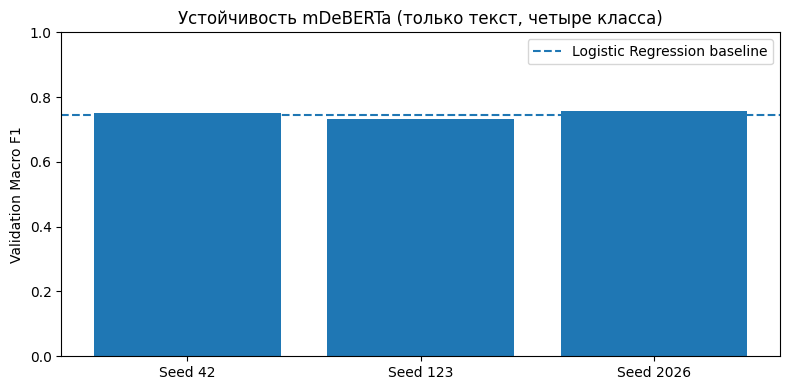

Тестовая выборка не использовалась. Сравнение сохранено в /kaggle/working/bank_risk_multiclass_seed_stability


In [7]:
# ФАКТИЧЕСКИЕ результаты из ранее скачанных CSV, НЕ повторное обучение
REFERENCE_SEED42 = json.loads('{"name": "text_standard", "mode": "text", "loss_mode": "standard", "seed": 42, "max_length": 256, "epochs": 6, "learning_rate": 2e-05, "dataset_sha256": "52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3", "macro_f1": 0.7500282109800939, "risk_macro_f1": 0.6718181818181819, "weighted_f1": 0.9698130665182122, "accuracy": 0.970860927152318, "macro_precision": 0.8079798331015299, "macro_recall": 0.714572927072927, "risk_recall": 0.6236263736263736, "f1_no_risk": 0.98465829846583, "f1_cyber_risk": 0.75, "f1_operational_risk": 0.72, "f1_regulatory_risk": 0.5454545454545454}')
REFERENCE_BASELINE = json.loads('{"name": "LogisticRegression_text_balanced", "algorithm": "LogisticRegression", "mode": "text", "class_weight": "balanced", "dataset_sha256": "52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3", "duration_sec": 4.73, "macro_f1": 0.7446479542288609, "risk_macro_f1": 0.664179606103381, "weighted_f1": 0.9719080102829512, "accuracy": 0.9735099337748344, "macro_precision": 0.8760358715808994, "macro_recall": 0.7176698301698301, "risk_recall": 0.6272893772893773, "f1_no_risk": 0.9860529986052998, "f1_cyber_risk": 0.7894736842105263, "f1_operational_risk": 0.7586206896551724, "f1_regulatory_risk": 0.4444444444444444}')
assert REFERENCE_SEED42['dataset_sha256'] == DATA_SHA
assert REFERENCE_BASELINE['dataset_sha256'] == DATA_SHA
assert REFERENCE_SEED42['seed'] == 42
assert REFERENCE_SEED42['name'] == 'text_standard'
assert REFERENCE_BASELINE['name'] == 'LogisticRegression_text_balanced'

records = [dict(REFERENCE_SEED42, name='text_standard_seed42_reference', source='previous_kaggle_output')]
for cfg in CONFIGS:
    path = OUT/'runs'/cfg['name']/'metrics.json'
    if path.exists():
        rec = json.loads(path.read_text(encoding='utf-8'))
        assert rec['dataset_sha256'] == DATA_SHA
        for key in ('seed','max_length','epochs','learning_rate','mode','loss_mode'):
            assert rec[key] == cfg[key], (key,rec[key],cfg[key])
        records.append(dict(rec, source='current_seed_experiment'))

seed_df = pd.DataFrame(records).sort_values('seed').reset_index(drop=True)
# Удаляем техническую матрицу ошибок из сводной таблицы, но оставляем per-class метрики.
cols=['seed','name','source','macro_f1','risk_macro_f1','macro_precision','macro_recall',
      'f1_no_risk','f1_cyber_risk','f1_operational_risk','f1_regulatory_risk','dataset_sha256']
seed_df[cols].to_csv(OUT/'seed_stability.csv', index=False)
score=seed_df['macro_f1']
summary={
    'task':'risk_type_4cls',
    'input_mode':'text',
    'metric':'validation_macro_f1',
    'dataset_sha256':DATA_SHA,
    'original_model_seed':42,
    'baseline_model':REFERENCE_BASELINE['name'],
    'baseline_validation_macro_f1':float(REFERENCE_BASELINE['macro_f1']),
    'num_available_seeds':int(len(seed_df)),
    'seeds':seed_df['seed'].astype(int).tolist(),
    'mean_macro_f1':float(score.mean()),
    'sample_std_macro_f1':float(score.std(ddof=1)) if len(score)>1 else None,
    'min_macro_f1':float(score.min()),
    'max_macro_f1':float(score.max()),
    'seeds_above_baseline':int((score > REFERENCE_BASELINE['macro_f1']).sum()),
    'selection_policy':'original seed 42 remains frozen; no seed selected by these repeats',
    'test_evaluated':False,
}
save_json(OUT/'seed_stability_summary.json',summary)
print('Logistic Regression baseline Validation Macro F1:',round(REFERENCE_BASELINE['macro_f1'],4))
display(seed_df[cols[:-1]].round(4))
print('Среднее:',round(summary['mean_macro_f1'],4),
      '| стандартное отклонение:',None if summary['sample_std_macro_f1'] is None else round(summary['sample_std_macro_f1'],4))

fig,ax=plt.subplots(figsize=(8,4))
ax.bar([f'Seed {s}' for s in seed_df['seed']],seed_df['macro_f1'])
ax.axhline(float(REFERENCE_BASELINE['macro_f1']),linestyle='--',label='Logistic Regression baseline')
ax.set_ylim(0,1); ax.set_ylabel('Validation Macro F1')
ax.set_title('Устойчивость mDeBERTa (только текст, четыре класса)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'seed_stability_macro_f1.png',dpi=150)
plt.show()

print('Тестовая выборка не использовалась. Сравнение сохранено в',OUT)

## 7. Интерпретация устойчивости

Два из трёх запусков превышают baseline на validation, один уступает. Устойчивое преимущество mDeBERTa не установлено. Для финальной оценки сохранена исходная модель seed 42: дополнительные запуски не служили поиском лучшего seed. Итоговое сравнение на test представлено в ноутбуке 11.

## 8. Артефакты эксперимента

Сводные результаты находятся в `results/multiclass/stability/seed_stability.csv` и `seed_stability_summary.json`. Веса повторов хранятся отдельно в Kaggle: `bank_risk_multiclass_seed_stability/runs/text_standard_seed123/best_model/model.safetensors` и аналогичный путь для seed 2026.

В ноутбуке восстановлены реальные execution_count, output и история обучения из сохранённого выполнения Kaggle. Завершение запусков также подтверждается сводными CSV и JSON; веса моделей доступны в Kaggle, но в локальный проект не включены.